<a href="https://colab.research.google.com/github/vishwa24816/Fama-French-factor-regression/blob/main/Fama_French_factor_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install yfinance statsmodels pandas-datareader pandas numpy matplotlib -q

import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pandas_datareader.data as web
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

plt.style.use("seaborn-v0_8")
pd.set_option("display.float_format", "{:.6f}".format)

In [15]:
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN", "JPM", "JNJ", "XOM", "PG", "KO", "WMT"]
weights = np.array([0.10] * len(tickers))  # equal-weighted portfolio

end_date = datetime.today()
start_date = end_date - timedelta(days=365 * 20)

print(f"Tickers: {tickers}")
print(f"Period: {start_date.date()} to {end_date.date()}")

Tickers: ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'JPM', 'JNJ', 'XOM', 'PG', 'KO', 'WMT']
Period: 2006-11-07 to 2026-11-02


In [16]:
raw = yf.download(tickers, start=start_date, end=end_date, interval="1d",
                  auto_adjust=True, progress=False)
prices = raw["Close"].dropna()
print(prices.shape)
prices.tail()

(5027, 10)


Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,PG,WMT,XOM
Date,,,,,,,,,,
2026-10-27,347.100006,253.100006,320.579987,268.730011,335.790009,91.180000,531.330017,159.229996,119.320000,179.910004
2026-10-28,343.829987,254.600006,324.890015,271.040009,339.299988,91.730003,531.010010,158.259995,118.769997,182.020004
2026-10-29,348.910004,243.789993,283.820007,275.200012,343.579987,92.820000,530.140015,160.589996,121.250000,183.289993
2026-10-30,344.630005,240.350006,279.839996,273.200012,337.040009,94.080002,521.909973,161.570007,123.510002,187.250000
2026-11-02,341.160004,253.460007,283.779999,268.399994,341.299988,95.220001,523.440125,162.940002,125.820000,181.669907


In [17]:
stock_returns = prices.pct_change().dropna()
portfolio_returns = stock_returns.dot(weights)
portfolio_returns.name = "Portfolio"

print(portfolio_returns.describe())

count   5026.000000
mean       0.000712
std        0.011347
min       -0.092365
25%       -0.003878
50%        0.000908
75%        0.005855
max        0.114902
Name: Portfolio, dtype: float64


In [18]:
ff3 = web.DataReader("F-F_Research_Data_Factors_daily", "famafrench",
                     start=start_date, end=end_date)[0]
ff3 = ff3 / 100  # convert from percent to decimal
ff3.index = pd.to_datetime(ff3.index.to_timestamp() if hasattr(ff3.index, "to_timestamp") else ff3.index)
ff3.head()

,Mkt-RF,SMB,HML,RF
Date,,,,
2006-11-07,0.002300,0.000700,-0.002400,0.000200
2006-11-08,0.002900,0.002800,0.003100,0.000200
2006-11-09,-0.005800,-0.004700,0.003100,0.000200
2006-11-10,0.002700,0.006500,0.000800,0.000200
2006-11-13,0.002700,0.001600,0.000100,0.000200


In [19]:
data = pd.concat([portfolio_returns, ff3], axis=1, join="inner").dropna()
data["Excess"] = data["Portfolio"] - data["RF"]

print(f"Observations after merge: {len(data)}")
data.head()

Observations after merge: 5003


,Portfolio,Mkt-RF,SMB,HML,RF,Excess
Date,,,,,,
2006-11-08,0.004811,0.002900,0.002800,0.003100,0.000200,0.004611
2006-11-09,-0.004738,-0.005800,-0.004700,0.003100,0.000200,-0.004938
2006-11-10,0.001314,0.002700,0.006500,0.000800,0.000200,0.001114
2006-11-13,0.003727,0.002700,0.001600,0.000100,0.000200,0.003527
2006-11-14,0.010494,0.007100,0.009300,-0.002400,0.000200,0.010294


In [20]:
X = sm.add_constant(data[["Mkt-RF", "SMB", "HML"]])
y = data["Excess"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Excess   R-squared:                       0.868
Model:                            OLS   Adj. R-squared:                  0.868
Method:                 Least Squares   F-statistic:                     4799.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:12:35   Log-Likelihood:                 20375.
No. Observations:                5003   AIC:                        -4.074e+04
Df Residuals:                    4999   BIC:                        -4.071e+04
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003   5.57e-05      4.677      0.0

In [21]:
results = pd.DataFrame({
    "Coefficient": model.params,
    "t-stat": model.tvalues,
    "p-value": model.pvalues
})
results["Significant (5%)"] = results["p-value"] < 0.05

print(f"Alpha (annualized): {model.params['const'] * 252:.4%}")
print(f"R-squared: {model.rsquared:.4f}")
results

Alpha (annualized): 6.5632%
R-squared: 0.8685


,Coefficient,t-stat,p-value,Significant (5%)
const,0.000260,4.677309,0.000003,True
Mkt-RF,0.862989,116.011677,0.000000,True
SMB,-0.250516,-16.129871,0.000000,True
HML,0.000421,0.035304,0.971837,False


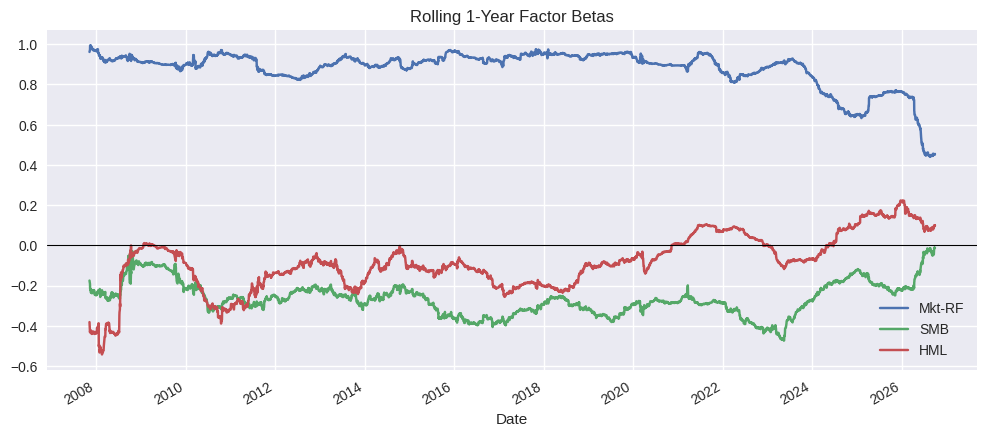

In [22]:
window = 252
rolling_betas = []
for i in range(window, len(data)):
    sub = data.iloc[i - window:i]
    Xr = sm.add_constant(sub[["Mkt-RF", "SMB", "HML"]])
    m = sm.OLS(sub["Excess"], Xr).fit()
    rolling_betas.append(m.params[["Mkt-RF", "SMB", "HML"]].values)

rolling_betas = pd.DataFrame(rolling_betas, index=data.index[window:],
                             columns=["Mkt-RF", "SMB", "HML"])

rolling_betas.plot(figsize=(12, 5), title="Rolling 1-Year Factor Betas")
plt.axhline(0, color="black", lw=0.8)
plt.show()

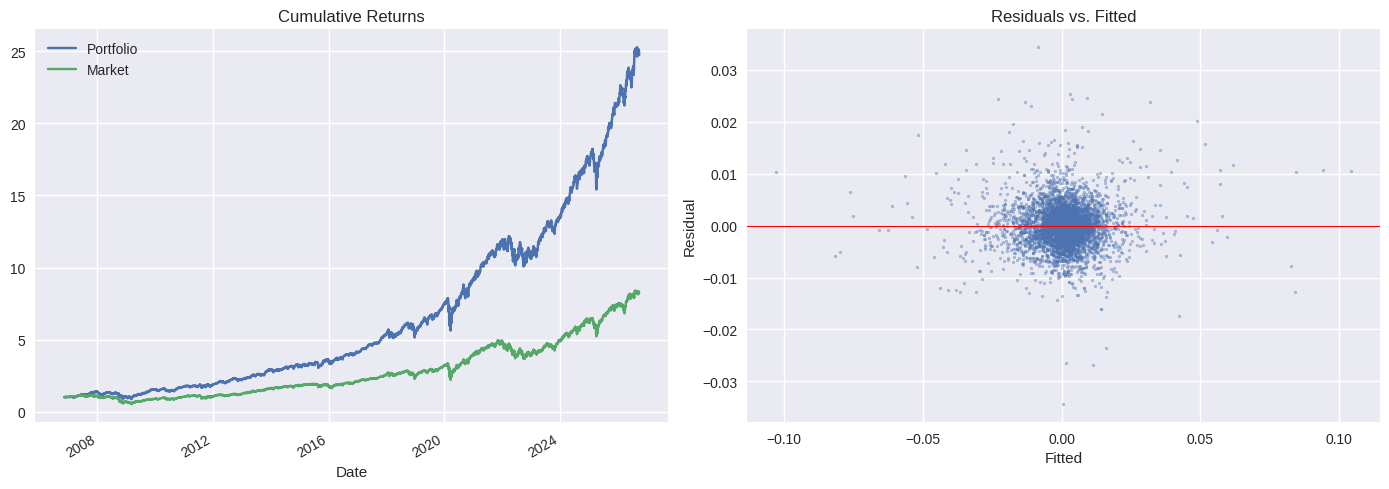

In [23]:
cum_port = (1 + data["Portfolio"]).cumprod()
cum_mkt = (1 + data["Mkt-RF"] + data["RF"]).cumprod()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cum_port.plot(ax=ax[0], label="Portfolio")
cum_mkt.plot(ax=ax[0], label="Market")
ax[0].set_title("Cumulative Returns")
ax[0].legend()

ax[1].scatter(model.fittedvalues, model.resid, s=4, alpha=0.4)
ax[1].axhline(0, color="red", lw=0.8)
ax[1].set_title("Residuals vs. Fitted")
ax[1].set_xlabel("Fitted")
ax[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()